# 🎯 Module 06: Embeddings and Semantic Search

> **Course:** Generative AI — From Scratch to GenAI Engineer  
> **Stage:** Stage 2 — Retrieval and RAG Foundations  
> **Module:** 06 — Embeddings and Semantic Search  
> **Planned Date:** July 13, 2026  
> **Level:** Beginner → Advanced  
> **Prerequisites:** Python, Modules 01–05  
> **Previous:** 05 — Structured Outputs and Validation  
> **Next:** 07 — Vector Databases and Retrieval

---

Now we learn how to compare **meaning**, not just words.

In this module we'll cover:

- What **embeddings** are
- How embeddings fit into **GenAI pipelines**
- **Tokens, token embeddings, hidden states, text embeddings**
- **Keyword search** vs **semantic search**
- **Cosine similarity**, **dot product**, **Euclidean distance**
- **Generating real embeddings** from an API
- Building a **semantic search engine** in Python
- **Embedding design decisions** (dimensions, normalization, compatibility)
- **Chunking** long documents
- **Evaluating search quality** (Precision@k, Recall@k, MRR)
- **Common mistakes**
- A **practical lab**: semantic search engine

## 📚 Learning Objectives

By the end of this module you should be able to:

1. Explain **what embeddings are** and why they matter
2. Understand how **text becomes a numerical vector**
3. Distinguish **tokenization / tokens / embeddings / hidden states**
4. Compare **semantic search** with **keyword search**
5. Understand **cosine similarity**, **dot product**, **Euclidean distance**
6. Generate embeddings using a **model provider**
7. Build a **semantic search engine** in Python
8. Understand **embedding dimensions**, **normalization**, **model selection**
9. Evaluate search quality using **Precision@k** & **MRR**
10. Prepare text embeddings for **RAG**

---
## ⚙️ 0. Setup & Imports

This notebook is **safe to run without an API key** — the semantic search math runs locally, and the real embedding generation is guarded.

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)

HAS_KEY   = bool(os.getenv('OPENAI_API_KEY')) or bool(os.getenv('LLM_API_KEY'))
HAS_MODEL = bool(os.getenv('LLM_MODEL'))

print('✅ Setup ready.')
print(f'API key present : {HAS_KEY}')
print(f'Model configured: {HAS_MODEL}')

if not HAS_KEY:
    print('\n⚠️ Live embedding calls disabled. Local similarity & search logic still runs.')

✅ Setup ready.
API key present : False
Model configured: False

⚠️ Live embedding calls disabled. Local similarity & search logic still runs.


---
## 🧠 1. What Are Embeddings?

An **embedding** is a **numerical representation** of an item (text, image, audio) designed to capture **useful characteristics** of that item.

### Example

Consider these sentences:

- "How can I reset my password?"
- "I forgot my login credentials."
- "What is the weather today?"

The **first two have different words but similar meanings** → their embeddings will be **close**.
The third is unrelated → its embedding will be **far away**.

```python
vector_a = [0.12, 0.84, -0.31, 0.55]   # reset password
vector_b = [0.15, 0.79, -0.28, 0.51]   # forgot login
vector_c = [-0.62, 0.14, 0.91, -0.23]  # weather
```

> ⚠️ Real embeddings have **hundreds or thousands** of dimensions — these 4D values are illustrative only.

**Key idea:** Embeddings let apps **compare meaning** numerically instead of only matching words.

---
## 🔗 2. How Embeddings Fit into GenAI

```text
Documents
    |
    v
Text Preprocessing
    |
    v
Embedding Model
    |
    v
Numerical Vectors
    |
    v
Similarity Search
    |
    v
Relevant Documents
    |
    v
LLM Application or RAG Pipeline
```

### Use cases

- Semantic search
- Document retrieval
- Recommendation systems
- Duplicate detection
- Clustering similar text
- Finding related support tickets
- **RAG**

> ⚠️ **An embedding model ≠ a generative LLM.**  
> Embedding models produce **vectors**; generative models produce **content**.

---
## 🧩 3. Tokens, Embeddings, and Hidden States

| Concept | Meaning |
| --- | --- |
| **Tokenization** | Splits text into tokens |
| **Token** | A unit processed by a model (word, part, punctuation) |
| **Token embedding** | A vector associated with a **single token** |
| **Hidden state** | A model's **contextual** representation during computation |
| **Text embedding** | A vector representing a **sentence / passage / document** |

```text
Text: "The server is unavailable"
        |
        v
Tokenizer
        |
        v
Token IDs
        |
        v
Embedding Model
        |
        v
Text Vector
        |
        v
Similarity Comparison
```

> You generally **don't** need to implement the internal pooling/projection — you just call the embedding API.

---
## ⚖️ 4. Keyword Search vs Semantic Search

### Keyword search

Query: `password recovery`  
→ Prioritizes documents containing those **exact words**.

### Semantic search

Query: `I cannot access my account because I forgot my password.`  
→ May retrieve `Steps to reset your login credentials` — even without the same words.

| Feature | Keyword Search | Semantic Search |
| --- | --- | --- |
| Signal | Words / terms | Learned vectors |
| Exact terms | Often effective | Depends on model |
| Different wording | Struggles | Retrieves similar meanings |
| Numeric IDs | Very effective | May not be reliable |
| Synonyms / paraphrase | Depends on method | Often handled naturally |
| Common use | Codes, names, filters | Questions, docs, concepts |

> **Neither is universally better.** Production systems often **combine** both.

---
## 📐 5. Understanding Vector Similarity

### 5.1 Cosine Similarity

$$\text{cosine}(A, B) = \frac{A \cdot B}{\|A\| \, \|B\|}$$

- `A · B` = dot product
- `\|A\|, \|B\|` = vector magnitudes
- Range: `-1 … +1`
- Higher → more similar (for models designed for cosine retrieval)

> ⚠️ Not a universal probability — it depends on the model.

### 5.2 Dot Product

$$A \cdot B = \sum_{i=1}^{n} A_i B_i$$

- For **normalized** vectors → same ranking as cosine
- For **unnormalized** vectors → magnitude affects the score

### 5.3 Euclidean Distance

$$d(A, B) = \sqrt{\sum_{i=1}^{n} (A_i - B_i)^2}$$

- **Smaller** distance → more similar

> Use the metric **recommended for your embedding model**.

---
## 🧮 6. Calculate Similarity with Python

We start with **hand-crafted vectors** to build intuition.

In [2]:
# Implement cosine similarity and Euclidean distance from scratch
def cosine_similarity(vector_a, vector_b):
    a = np.asarray(vector_a, dtype=float)
    b = np.asarray(vector_b, dtype=float)

    if a.ndim != 1 or b.ndim != 1:
        raise ValueError('Vectors must be one-dimensional.')
    if a.shape != b.shape:
        raise ValueError('Vectors must have the same dimensions.')

    na = np.linalg.norm(a)
    nb = np.linalg.norm(b)
    if na == 0 or nb == 0:
        raise ValueError('Cosine similarity is undefined for zero vectors.')
    return float(np.dot(a, b) / (na * nb))


def euclidean_distance(vector_a, vector_b):
    a = np.asarray(vector_a, dtype=float)
    b = np.asarray(vector_b, dtype=float)
    if a.shape != b.shape:
        raise ValueError('Vectors must have the same dimensions.')
    return float(np.linalg.norm(a - b))


# Demo with hand-crafted vectors
va = [0.8, 0.2, 0.5]
vb = [0.7, 0.3, 0.4]
vc = [-0.5, 0.8, -0.1]

print(f'cos(A, B) = {cosine_similarity(va, vb):.4f}')
print(f'cos(A, C) = {cosine_similarity(va, vc):.4f}')
print()
print(f'dist(A, B) = {euclidean_distance(va, vb):.4f}')
print(f'dist(A, C) = {euclidean_distance(va, vc):.4f}')

cos(A, B) = 0.9885
cos(A, C) = -0.3170

dist(A, B) = 0.1732
dist(A, C) = 1.5524


---
## 🚀 7. Generate Real Text Embeddings

Now we use a **real embedding model**.

### Install

```bash
pip install openai python-dotenv numpy
```

### `.env`

```text
OPENAI_API_KEY=your_api_key_here
```

### Basic usage

```python
response = client.embeddings.create(
    model='text-embedding-3-small',
    input=texts,
)
vectors = [item.embedding for item in response.data]
```

> ⚠️ Model names and dimensions change over time. Check your provider's current docs.

In [3]:
# A reusable embedding function with a local fallback for offline demos
def embed_texts(texts):
    """Return a list of embedding vectors.
    Uses the OpenAI embeddings API if OPENAI_API_KEY is available.
    Otherwise, falls back to a deterministic local pseudo-embedding
    so the rest of the notebook remains runnable and testable."""
    if not texts:
        return []

    if os.getenv('OPENAI_API_KEY'):
        try:
            from openai import OpenAI
            from dotenv import load_dotenv
            load_dotenv()
            client = OpenAI()
            response = client.embeddings.create(
                model='text-embedding-3-small',
                input=texts,
            )
            ordered = sorted(response.data, key=lambda x: x.index)
            return [item.embedding for item in ordered]
        except Exception as e:
            print(f'Live embedding call failed: {type(e).__name__}: {e}')
            print('Falling back to local pseudo-embeddings.')

    # Local fallback: deterministic hashing-based pseudo-embeddings
    import hashlib
    DIM = 64
    out = []
    for text in texts:
        h = hashlib.sha256(text.encode('utf-8')).digest()
        # Deterministic vector from hash bytes
        vec = np.frombuffer(h, dtype=np.uint8).astype(float)
        vec = np.resize(vec, DIM)
        vec = vec / (np.linalg.norm(vec) + 1e-9)
        out.append(vec.tolist())
    return out


documents = [
    'Reset your password from the account settings page.',
    'Update your billing details in the subscription portal.',
    'Troubleshoot a server that is not responding.',
    'Recover access when you forget your login credentials.',
]

doc_vectors = embed_texts(documents)
print('Documents:', len(documents))
print('Vector dimensions:', len(doc_vectors[0]))
print('First 5 values of first vector:', [round(v, 4) for v in doc_vectors[0][:5]])

Documents: 4
Vector dimensions: 64
First 5 values of first vector: [0.0973, 0.0566, 0.089, 0.03, 0.1298]


---
## 🔍 8. Build a Simple Semantic Search Engine

### What the code does

1. Generate an embedding for the query
2. Compare query vector with stored document vectors
3. Compute **cosine similarity**
4. Rank documents
5. Return the **top-k** results

In [4]:
def semantic_search(query, documents, document_vectors, top_k=3):
    if len(documents) != len(document_vectors):
        raise ValueError('Each document must have a corresponding vector.')
    if not documents:
        return []
    if not query.strip():
        raise ValueError('Query cannot be empty.')
    if top_k < 1:
        raise ValueError('top_k must be at least 1.')

    query_vector = embed_texts([query])[0]

    matrix = np.asarray(document_vectors, dtype=float)
    q = np.asarray(query_vector, dtype=float)

    if matrix.ndim != 2 or q.ndim != 1:
        raise ValueError('Unexpected embedding dimensions.')
    if matrix.shape[1] != q.shape[0]:
        raise ValueError('Query and document dimensions do not match.')

    matrix_norms = np.linalg.norm(matrix, axis=1)
    q_norm = np.linalg.norm(q)
    if q_norm == 0 or np.any(matrix_norms == 0):
        raise ValueError('Cannot compare zero vectors.')

    scores = (matrix @ q) / (matrix_norms * q_norm)
    ranked = np.argsort(scores)[::-1][:top_k]
    return [(documents[i], float(scores[i])) for i in ranked]


# Demo
query = 'I cannot log in because I forgot my password'
results = semantic_search(query, documents, doc_vectors, top_k=3)

print(f'Query: {query}')
print('Top results:')
for rank, (doc, score) in enumerate(results, start=1):
    print(f'  {rank}. score={score:.4f}  {doc}')

Query: I cannot log in because I forgot my password
Top results:
  1. score=0.8400  Reset your password from the account settings page.
  2. score=0.7979  Troubleshoot a server that is not responding.
  3. score=0.7348  Recover access when you forget your login credentials.


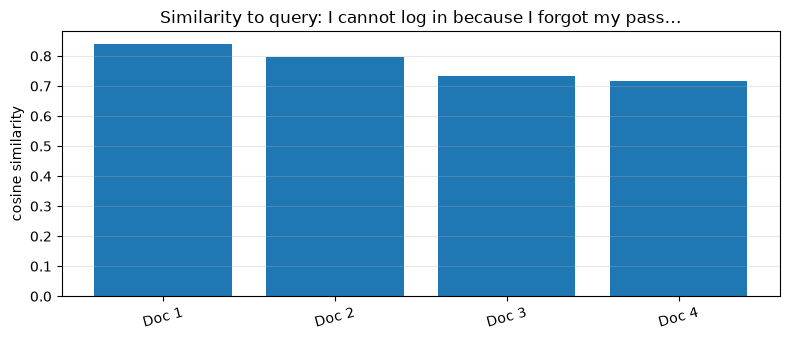

In [5]:
# Visualize the similarity scores
scores = [semantic_search(query, documents, doc_vectors, top_k=len(documents))]
ranked = semantic_search(query, documents, doc_vectors, top_k=len(documents))
labels = [f'Doc {i+1}' for i in range(len(documents))]
scores = [s for _, s in ranked]

plt.figure(figsize=(8, 3.5))
plt.bar(labels, scores)
plt.ylabel('cosine similarity')
plt.title(f'Similarity to query: {query[:40]}…')
plt.xticks(rotation=15)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

---
## 🎛️ 9. Important Embedding Design Decisions

### 9.1 Embedding dimensions

- Hundreds or thousands of values
- **Higher ≠ always better** — evaluate on your task

### 9.2 Normalize or not?

- Some systems normalize vectors to **magnitude 1**
- Normalized → cosine similarity = dot product
- ⚠️ Don't assume every model returns normalized vectors

### 9.3 Query & document compatibility

- **Same model** for both sides
- **Consistent dimensions**
- Follow model-specific **formatting**
- **Re-embed** when switching models

### 9.4 Chunking long documents

```text
Long Document
      |
      v
Split into Chunks
      |
      v
Generate an Embedding for Each Chunk
      |
      v
Store Text + Metadata + Vector
```

> A **single vector** for an entire long document may not be sufficient for **precise retrieval**.

---
## 📊 10. Evaluate Semantic Search Quality

Metrics:

- **Precision@k** — fraction of top-k results that are relevant
- **Recall@k** — fraction of known relevant docs appearing in the top-k
- **MRR** — how highly the first relevant result is ranked
- **Latency** — how long retrieval takes
- **Cost** — embedding + query processing

$$\text{Precision@k} = \frac{\text{Relevant results in top-}k}{k}$$

> ⚠️ **A high similarity score ≠ relevance.** Thresholds must be **calibrated** on your dataset.

In [6]:
# A tiny evaluation harness for semantic search
eval_cases = [
    {
        'query': 'I forgot my password',
        'relevant': ['Reset your password from the account settings page.'],
    },
    {
        'query': 'My subscription payment information is wrong',
        'relevant': ['Update your billing details in the subscription portal.'],
    },
    {
        'query': 'The server is not responding',
        'relevant': ['Troubleshoot a server that is not responding.'],
    },
]

def precision_at_k(results, relevant, k):
    top = [doc for doc, _ in results[:k]]
    hits = sum(1 for doc in top if doc in relevant)
    return hits / k

def reciprocal_rank(results, relevant):
    for rank, (doc, _) in enumerate(results, start=1):
        if doc in relevant:
            return 1.0 / rank
    return 0.0

precisions, rrs = [], []
for case in eval_cases:
    results = semantic_search(case['query'], documents, doc_vectors, top_k=3)
    p = precision_at_k(results, case['relevant'], k=3)
    rr = reciprocal_rank(results, case['relevant'])
    precisions.append(p)
    rrs.append(rr)
    print(f'Query: {case["query"]!r}')
    print(f'  P@3 = {p:.2f}   RR = {rr:.2f}')

print()
print(f'Mean Precision@3 = {np.mean(precisions):.3f}')
print(f'MRR              = {np.mean(rrs):.3f}')

Query: 'I forgot my password'
  P@3 = 0.33   RR = 0.50
Query: 'My subscription payment information is wrong'
  P@3 = 0.33   RR = 0.33
Query: 'The server is not responding'
  P@3 = 0.33   RR = 0.50

Mean Precision@3 = 0.333
MRR              = 0.444


---
## ⚠️ 11. Common Mistakes

- Treating embeddings as **human-readable meanings**
- Assuming **similar words → similar vectors**
- Assuming **high similarity score → relevance**
- Comparing vectors from **incompatible models**
- **Re-calculating every doc embedding** for every query
- Ignoring **input limits & rate limits**
- Using semantic search for **exact identifiers** without testing
- Forgetting to keep **text + metadata + vector** together
- Changing models without **re-embedding** stored docs
- Evaluating only **a few hand-picked examples**
- Sending **sensitive data** externally without checking privacy terms

---
## 🏋️ 12. Practical Lab — Semantic Search Engine

### 🎯 Objective
Build a Python search engine that retrieves **relevant documents by meaning**.

### Requirements

1. Dataset with **≥ 50 short documents**
2. Generate embeddings for each document
3. Store **text + vector together**
4. Implement **cosine similarity**
5. Build a **query interface**
6. Return **top-5** results with scores
7. Handle **empty queries & invalid dimensions**
8. Avoid re-embedding docs on every query
9. **≥ 15 test queries** with expected relevant docs
10. Measure **Precision@k** and **MRR**

### Suggested structure

```text
06-Embeddings-and-Semantic-Search/
├── README.md
├── .env.example
├── requirements.txt
├── src/
│   ├── embeddings.py
│   ├── similarity.py
│   ├── search.py
│   └── main.py
├── data/
│   └── documents.json
├── tests/
│   ├── test_similarity.py
│   └── test_search.py
└── evaluation/
    ├── queries.json
    └── evaluate.py
```

### Stretch goals

- Compare **two embedding models** on the same dataset
- Add **keyword search** and compare
- Implement **hybrid retrieval**
- **Cache** embeddings to reduce cost
- Add **metadata filters**
- Build a **FastAPI** endpoint

---
## 🎤 13. Interview Questions

**Q1. What is an embedding?**  
A numerical vector representing an item in a learned vector space — often used to compare semantic similarity.

**Q2. Token embedding vs text embedding?**  
Token embeddings represent **individual tokens**. Text embeddings represent **larger units** (sentence / passage / document).

**Q3. How does semantic search work?**  
It embeds a query & candidate docs into a compatible space, computes similarity/distance, and ranks documents.

**Q4. What is cosine similarity?**  
An angle-based similarity between two nonzero vectors.

**Q5. Cosine similarity vs Euclidean distance?**  
Cosine compares **direction**; Euclidean measures **straight-line distance**. Rankings can differ depending on magnitude/normalization.

**Q6. Why must query & doc embeddings use compatible models?**  
Incompatible models may produce vectors whose dimensions or learned spaces don't align → meaningless scores.

**Q7. Are embeddings always better than keyword search?**  
No. Keyword search is often better for exact IDs & literal matches. Semantic search helps with meaning & paraphrase. **Hybrid** combines strengths.

**Q8. What are Precision@k and Recall@k?**  
Precision@k = fraction of top-k results that are relevant. Recall@k = fraction of known relevant docs that appear in top-k.

**Q9. Why are embeddings important for RAG?**  
They retrieve semantically relevant chunks to supply as context to a generative model.

**Q10. When should document embeddings be regenerated?**  
When the text changes or a model/config change makes existing vectors incompatible.

---
## ✅ 14. Module Completion Checklist

- [ ] Explain embeddings in simple terms
- [ ] Distinguish **token embeddings** from **text embeddings**
- [ ] Explain keyword search vs semantic search
- [ ] Implement **cosine similarity**
- [ ] Generate real text embeddings using an API
- [ ] Build a **top-k semantic search** function
- [ ] Handle **invalid input & vector mismatches**
- [ ] Understand **normalization & embedding dimensions**
- [ ] Evaluate results with a **labeled dataset**
- [ ] Complete the **Semantic Search Engine** project

---
## 🏁 15. Key Takeaways

- **Embeddings** convert text into **numerical vectors** that can be compared
- **Semantic search** retrieves info based on **learned representations of meaning**
- **Cosine similarity** and other metrics help rank candidates
- Embedding quality depends on **model, task, data, retrieval setup**
- Search quality must be **measured** with labeled datasets
- Embeddings are a **core building block** for **RAG**, **recommendations**, and many GenAI apps

### 🧭 Golden Rule

> **Embeddings let you compare meaning. But similarity scores only matter if they retrieve the right documents — always evaluate on real queries.**

---

### 🔗 What's Next?

**Module 07 — Vector Databases and Retrieval**

- Store embeddings with **text + metadata**
- Retrieve **nearest neighbors** efficiently
- Build a **scalable retrieval layer** for RAG
- Vector indexes, ANN search, and filtering